# TP4 — Architecture Transformer : RNN, LSTM, GPT et BERT

| Informations académiques | Détails |
|---|---|
| Nom et prénom | Hachoum Mouad |
| Filière | INTELLIGENCE ARTIFICIELLE & SCIENCES DES DONNÉES |
| Année universitaire | 2026-2027 |
| Module | IA Générative Multimodale |
| Enseignant | Pr. Mohamed Youssfi |

Le notebook suit les deux parties du support officiel `architecture_transformer.ipynb`
(56 cellules), en particulier les exercices des cellules 37–54. Il compare trois
réseaux sur une sinusoïde, présente GPT-2 et BERT préentraînés, puis entraîne un
Transformer énergétique, un mini-GPT et un mini-BERT depuis zéro.
Les architectures et le protocole sont adaptés du support ; les corpus français,
graphiques et résultats sont produits pour ce TP avec l'assistance de Codex.
Aucune image du support n'est reproduite. Les modules voisins séparent seulement
les architectures, les données, la boucle d'entraînement et les expériences.

## Environnement et reprise

Python 3.11 et environnement UV isolé. Graine 42, float32, algorithmes déterministes,
TF32 désactivé et attention SDPA mathématique. Les trois petits réseaux sinus utilisent
le CPU pour éviter le coût de nombreux petits lancements CUDA ; les exercices plus
grands et les inférences utilisent le GPU disponible. Les durées restent propres à
ce matériel et incluent seulement les boucles indiquées dans le rapport.

Un checkpoint contient l'optimiseur, l'époque et les états aléatoires. Un entraînement
terminé à configuration identique est rechargé ; il n'est pas relancé silencieusement.
Les démonstrations préentraînées sont aussi sauvegardées après une vraie inférence.

In [1]:
import gc, importlib.metadata, inspect, json, platform, sys
from datetime import datetime, timezone
from pathlib import Path
import pandas as pd
import torch
from IPython.display import Code, Image, Markdown, display
from entrainement import ROOT, ecrire_json, empreinte, initialiser
import experiences, modeles, preentraines

initialiser()
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert Path(sys.prefix).resolve()==(ROOT/'.venv').resolve()
assert (ROOT/'data/ressources.json').is_file(), 'Lancer preparer_ressources.py avant le notebook.'
environnement={'python':platform.python_version(),'torch':torch.__version__,'cuda_runtime':torch.version.cuda,
    'cuda_disponible':torch.cuda.is_available(),'gpu':torch.cuda.get_device_name() if device.type=='cuda' else None,
    'graine':42,'threads_cpu':torch.get_num_threads(),'determinisme':True,'dtype':'float32',
    'versions':{n:importlib.metadata.version(n) for n in ['transformers','numpy','pandas','matplotlib','nbclient']}}
print(json.dumps(environnement,ensure_ascii=False,indent=2))
def voir(nom): display(Image(filename=str(ROOT/'figures'/nom)))

<TP4>\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
  "python": "3.11.9",
  "torch": "2.9.1+cu128",
  "cuda_runtime": "12.8",
  "cuda_disponible": true,
  "gpu": "NVIDIA GeForce RTX 3060 Laptop GPU",
  "graine": 42,
  "threads_cpu": 2,
  "determinisme": true,
  "dtype": "float32",
  "versions": {
    "transformers": "5.24.1",
    "numpy": "2.4.6",
    "pandas": "3.1.1",
    "matplotlib": "3.11.2",
    "nbclient": "0.11.0"
  }
}


# Partie 1 — Modèles séquentiels et modèles préentraînés

## A–E. Même sinusoïde, trois architectures

`sin(linspace(0,20,200))`, fenêtres de dix valeurs : **X=(190,10,1)** et **y=(190,1)**.
Les 150 premières cibles servent à apprendre et les 40 dernières à tester ; les fenêtres
peuvent partager des observations passées, mais la cible future n'entre jamais dans X.

| Modèle | Architecture imposée |
|---|---|
| SimpleRNN | RNN(1,16), dernière position, Linear(16,1) |
| SimpleLSTM | LSTM(1,16), une couche, dernière position, Linear(16,1) |
| MiniTransformer | Linear(1,16), positions apprises, un encodeur, 2 têtes, FF=32, dropout=0, sortie dernière position |

Adam(lr=0.01), MSELoss et 300 époques pour tous, en un lot de 150 séquences.
Le Transformer peut observer toute la fenêtre connue : aucun masque causal n'est
nécessaire ici puisque la valeur suivante n'est pas fournie.

class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=16, batch_first=True)
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.rnn(x)
        return self.sortie(etats[:, -1, :])

class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=16, num_layers=1, batch_first=True)
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.lstm(x)
        return self.sortie(etats[:, -1, :])

class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10):
        super().__init__()
        self.projection = nn.Linear(1, 16)
        self.positions = nn.Embedding(longueur_max, 16)
        couche = nn.TransformerEncoderLayer(d_model=16, nhead=2, dim_feedforward=32,
            dropout=0.0, batch_first=True)
        self.encodeur = nn.TransformerEncoder(couche, num_layers=1, enable_nested_tensor=False)
        self.sortie = nn.Linear(16, 1)

    def representations(self, x):
        indices = torch.arange(x.size(1), device=x.device)
        return self.encodeur(self.projection(x) + self.positions(indices).unsqueeze(0))

    def forward(self, x):
        return self.sortie(self.representations(x)[:, -1, :])

rnn : entraînement terminé réutilisé.


lstm : entraînement terminé réutilisé.


transformer_sinus : entraînement terminé réutilisé.


,mse,mae,rmse,cibles,parametres,secondes_train,rechargement
rnn,0.000028,0.004562,0.005256,40,321,0.938225,True
lstm,0.000003,0.001355,0.001582,40,1233,0.963037,True
transformer_sinus,0.000006,0.002041,0.002349,40,2433,2.026506,True


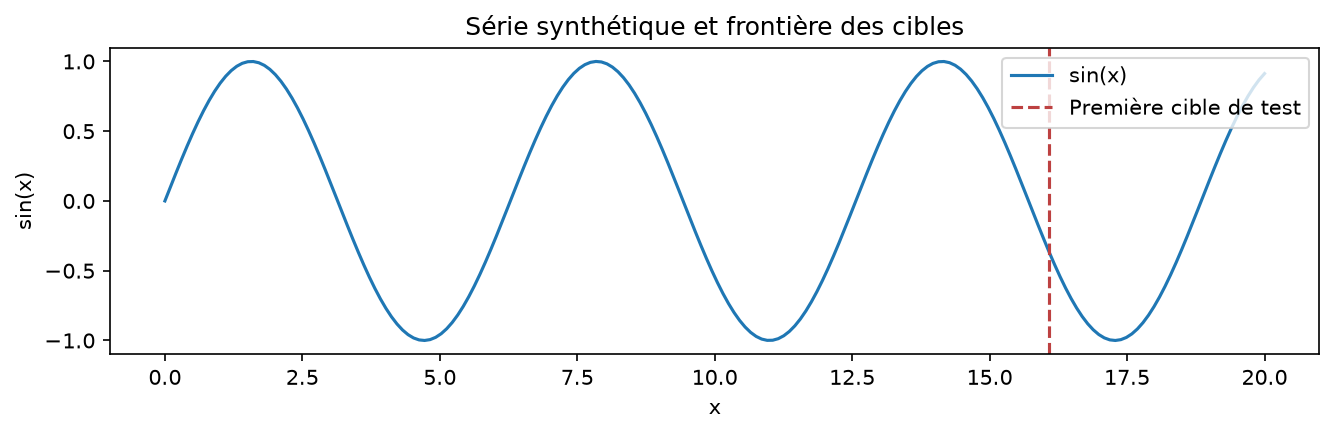

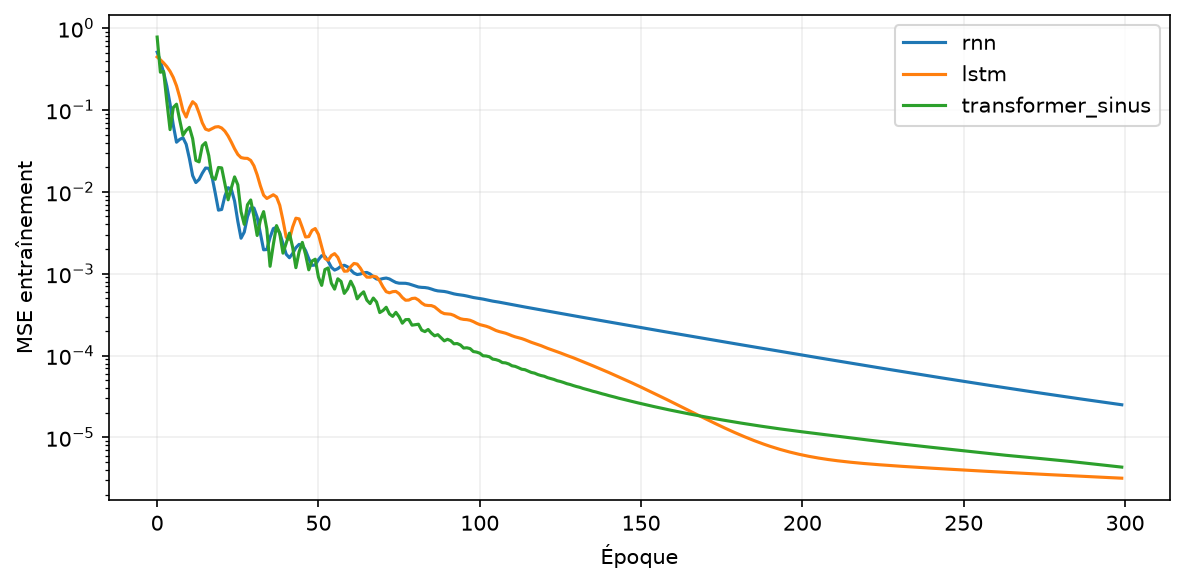

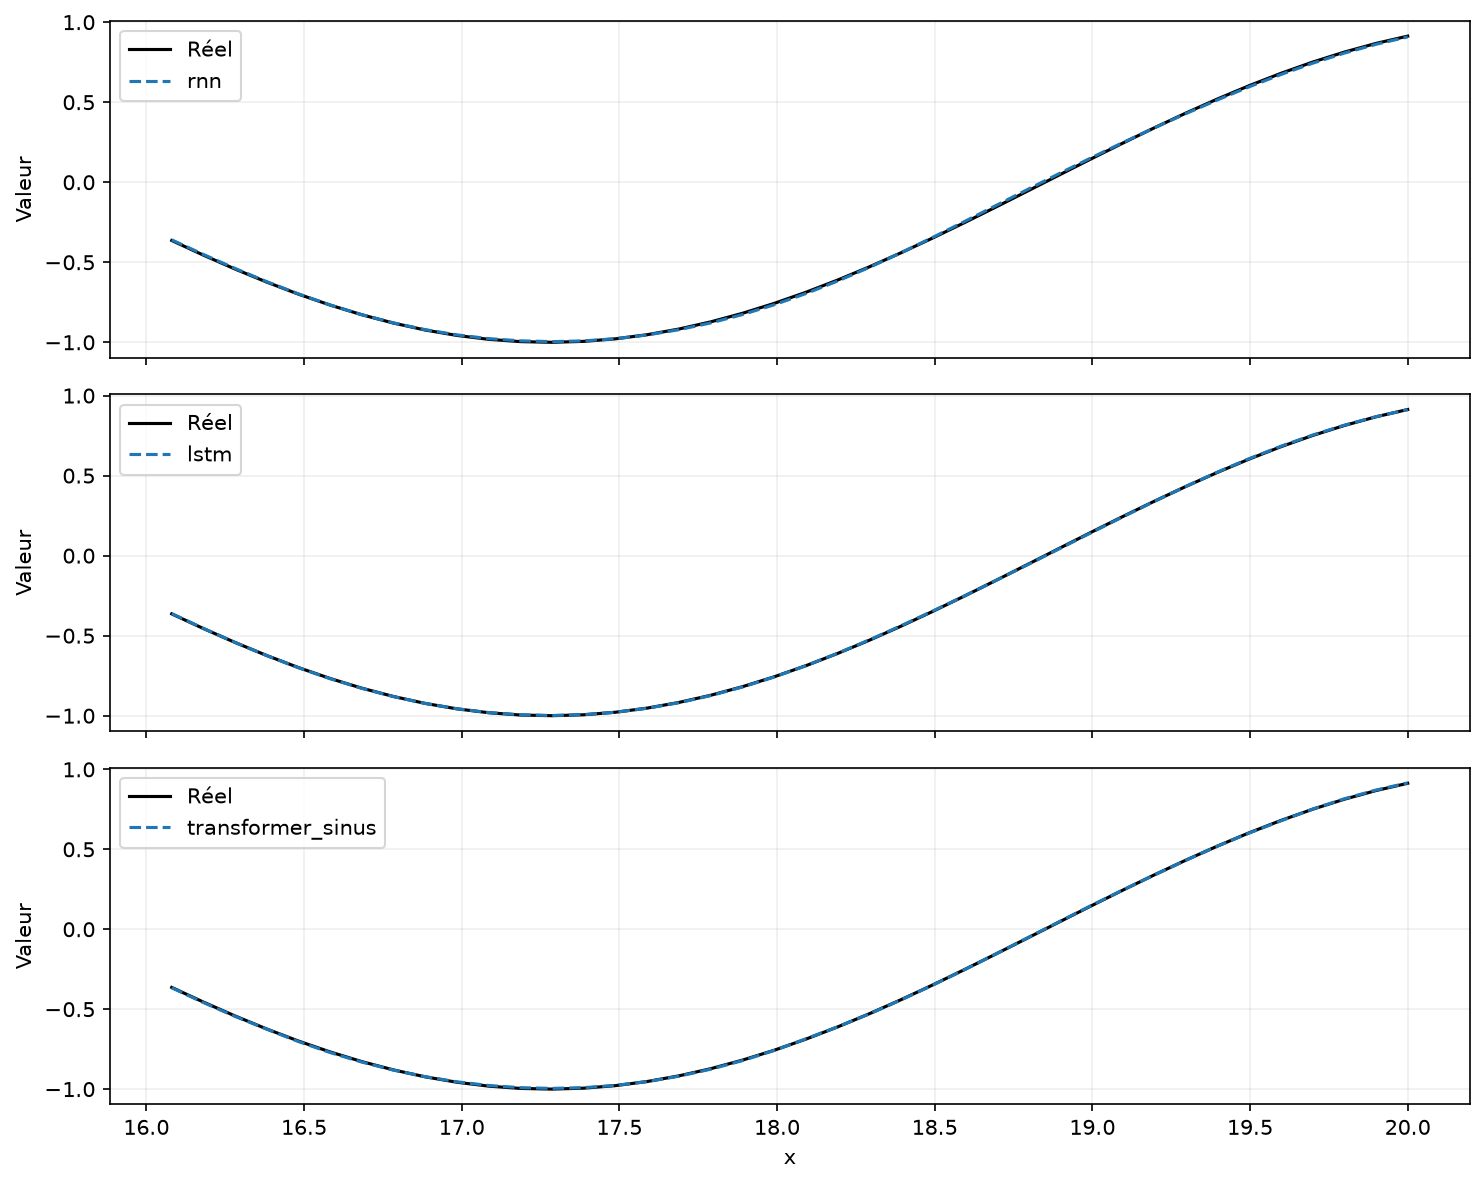

In [2]:
for classe in [modeles.SimpleRNN,modeles.SimpleLSTM,modeles.MiniTransformer]:
    display(Code(inspect.getsource(classe),language='python'))
resultat_sinus=experiences.sinus()
display(pd.DataFrame({n:{**r['metriques_test'],'parametres':r['parametres'],
    'secondes_train':r['secondes_entrainement'],'rechargement':r['rechargement']['reussi']}
    for n,r in resultat_sinus['modeles'].items()}).T)
for f in ['sinus_donnees.png','sinus_pertes.png','sinus_predictions.png']:voir(f)

Le RNN transmet un état caché ; le LSTM ajoute une mémoire contrôlée par des portes.
Le Transformer met les positions en relation par attention et doit recevoir leur ordre.
Une MSE faible sur cette seule courbe périodique ne démontre aucune supériorité générale.
Le nombre de paramètres et les durées doivent se lire avec la taille du jeu de données,
la graine, le matériel et le protocole à un pas. Il ne s'agit pas d'une prévision récursive.

## F–G. GPT-2 et BERT multilingue préentraînés

Ces deux modèles sont chargés avec AutoTokenizer et les classes AutoModel imposées,
sans mise à jour de leurs poids. GPT-2 utilise EOS comme padding et conserve un masque
d'attention explicite. L'amorce et les paramètres sont ceux du professeur :
`Artificial intelligence can help people`, 50 tokens nouveaux au maximum, température
0.8, top-p 0.9 et échantillonnage activé. EOS peut terminer la génération plus tôt.

Pour BERT, le premier texte est exactement celui du **code** du professeur,
« Rabat est la [MASK] Maroc. ». Le second ajoute « du » pour former une phrase complète.
Le masque est repéré dans les identifiants et la softmax porte sur le vocabulaire entier.

<!-- lecture-des-resultats -->
Dans cette exécution, **lstm** donne la plus faible MSE de test (2.5024247e-06). Le Transformer obtient une erreur intermédiaire avec davantage de paramètres et un temps plus long. Ces observations concernent uniquement cette sinusoïde et cette graine.

In [3]:
resultat_preentraine=preentraines.executer(device)
g=resultat_preentraine['gpt2']
print('Entrée GPT-2 :',g['amorce']);print('Identifiants :',g['input_ids']);print('Tokens :',g['tokens'])
print('Tokens nouveaux :',g['nouveaux_tokens']);print(g['texte_genere'])
for exemple in resultat_preentraine['bert_multilingue']['phrases']:
    print('\nBERT :',exemple['phrase'],'| position masque :',exemple['position_masque'])
    print('Input IDs :',exemple['input_ids'],'| somme softmax :',exemple['somme_probabilites'])
    display(pd.DataFrame(exemple['top5']))
print('Mémoire GPU après libération :',{n:r['memoire_gpu_apres_liberation_octets'] for n,r in resultat_preentraine.items()})

gpt2 : inférence réelle déjà sauvegardée, réutilisation.


bert_multilingue : inférence réelle déjà sauvegardée, réutilisation.


Entrée GPT-2 : Artificial intelligence can help people
Identifiants : [8001, 9542, 4430, 460, 1037, 661]
Tokens : ['Art', 'ificial', 'Ġintelligence', 'Ġcan', 'Ġhelp', 'Ġpeople']
Tokens nouveaux : 50
Artificial intelligence can help people understand the complexities of the world, and can help them understand the nature of their own lives, even if they do not live in the same country as the person in question.

In the United States, the National Science Foundation is working to develop

BERT : Rabat est la [MASK] Maroc. | position masque : 4
Input IDs : [101, 38929, 10176, 10109, 103, 48256, 119, 102] | somme softmax : 1.0000003576278687


,id,token,remplacement,probabilite,phrase
0,19968,capitale,capitale,0.428970,Rabat est la capitale Maroc.
1,10168,du,du,0.206551,Rabat est la du Maroc.
2,10104,de,de,0.062333,Rabat est la de Maroc.
3,11743,ville,ville,0.034584,Rabat est la ville Maroc.
4,38929,Rabat,Rabat,0.016728,Rabat est la Rabat Maroc.



BERT : Rabat est la [MASK] du Maroc. | position masque : 4
Input IDs : [101, 38929, 10176, 10109, 103, 10168, 48256, 119, 102] | somme softmax : 1.0


,id,token,remplacement,probabilite,phrase
0,19968,capitale,capitale,0.860621,Rabat est la capitale du Maroc.
1,11743,ville,ville,0.051898,Rabat est la ville du Maroc.
2,58257,préfecture,préfecture,0.050346,Rabat est la préfecture du Maroc.
3,38929,Rabat,Rabat,0.008458,Rabat est la Rabat du Maroc.
4,12185,capital,capital,0.005763,Rabat est la capital du Maroc.


Mémoire GPU après libération : {'gpt2': 34603008, 'bert_multilingue': 34603008}


GPT-2 prédit un token suivant, l'ajoute puis recommence avec une attention causale.
BERT retrouve un token masqué en utilisant le contexte situé à gauche et à droite.
Un token n'est pas toujours un mot : les propositions WordPiece marquées `##` sont
des sous-mots. Les scores softmax sont des préférences du modèle, pas des probabilités
de vérité. Les exemples sont de véritables sorties d'inférence ; les modèles et leurs
tenseurs sont libérés avant la suite.

# Partie 2 — Trois exercices

## Exercice 1 — Puissance électrique horaire

Le dataset UCI **Individual Household Electric Power Consumption** est crédité à
Georges Hebrail et Alice Berard (licence CC BY 4.0). `Global_active_power` est une
puissance moyenne en kW. Les minutes sont regroupées par heure ; une heure comportant
moins de 45 mesures valides devient NaN, sans supprimer sa position dans le calendrier.

Le découpage porte sur le calendrier : 70 % / 15 % / 15 %. La moyenne et l'écart-type
(ddof=1) proviennent uniquement du train. Une fenêtre contient 24 heures consécutives
et la cible suivante ; toute fenêtre avec NaN est rejetée. L'ensemble d'appartenance
est déterminé par la date de la cible. Le contexte observé peut donc commencer avant
la frontière, ce qui est disponible lors d'une prévision réelle à un pas.

EnergyTransformer : Linear(1,32), positions apprises pour 24 heures, deux encodeurs
(4 têtes, FF=128, dropout=0.1), Linear(32,1) sur la dernière position.
Adam(lr=0.001), batch=64, 20 époques maximum ; seul le minimum de perte de validation
sélectionne les poids. Le test n'est jamais consulté pour ce choix.

class EnergyTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(1, 32)
        self.positions = nn.Embedding(24, 32)
        couche = nn.TransformerEncoderLayer(d_model=32, nhead=4, dim_feedforward=128,
            dropout=0.1, batch_first=True)
        self.encodeur = nn.TransformerEncoder(couche, num_layers=2, enable_nested_tensor=False)
        self.sortie = nn.Linear(32, 1)

    def representations(self, x):
        indices = torch.arange(x.size(1), device=x.device)
        return self.encodeur(self.projection(x) + self.positions(indices).unsqueeze(0))

    def forward(self, x):
        return self.sortie(self.representations(x)[:, -1, :])

energy_transformer : entraînement terminé réutilisé.


{
  "moyenne_train_kw": 1.0864845599475577,
  "ecart_type_train_kw": 0.9287406664230875,
  "ddof": 1,
  "heures_total": 34589,
  "heures_manquantes": 438,
  "fin_train": 24212,
  "fin_validation": 29400,
  "fenetres": {
    "train": 23805,
    "validation": 5054,
    "test": 4932
  },
  "frontieres_cibles": [
    "2009-09-20 13:00:00",
    "2010-04-24 17:00:00"
  ],
  "sha256": "4259c9d7ece5dbee9ab8d53682baac68d791c864f0f64a52b4043cb3b90894b7",
  "lignes_minutes": 2075259,
  "valeurs_minutes_manquantes": 25979,
  "minimum_mesures_valides_par_heure": 45
}
Époque retenue : 17


,mse,mae,rmse,cibles
transformer,0.237783,0.339984,0.487630,4932.0
persistance,0.346197,0.389198,0.588385,4932.0
journaliere_24h,0.583506,0.513277,0.763876,4932.0


Sept jours : {'debut': '2010-04-25 00:00:00', 'fin': '2010-05-01 23:00:00', 'heures': 168, 'heures_sans_prediction': 0}


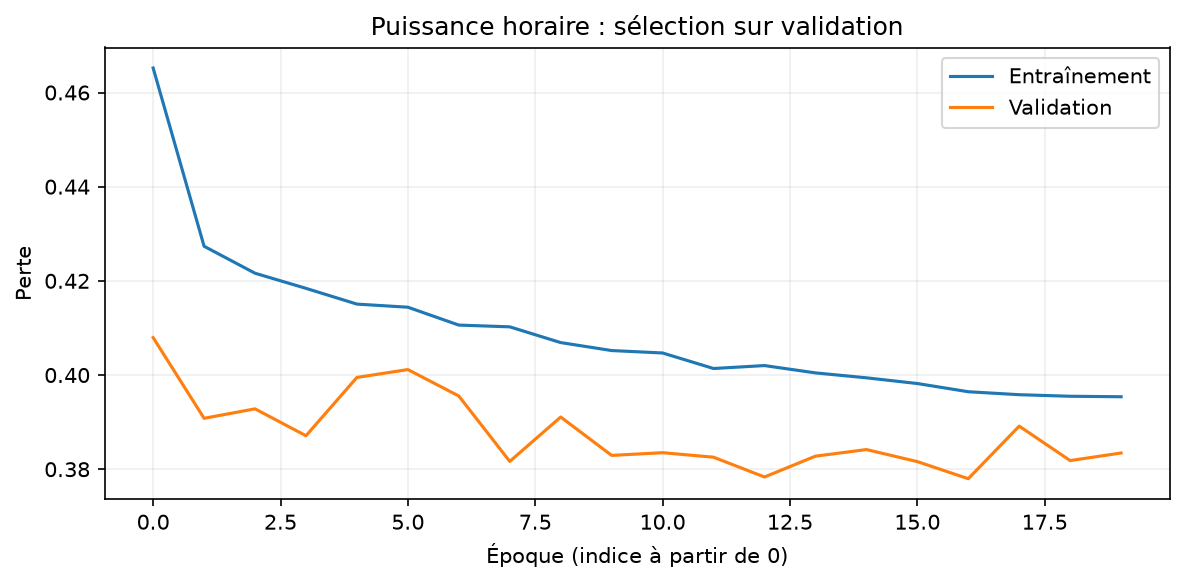

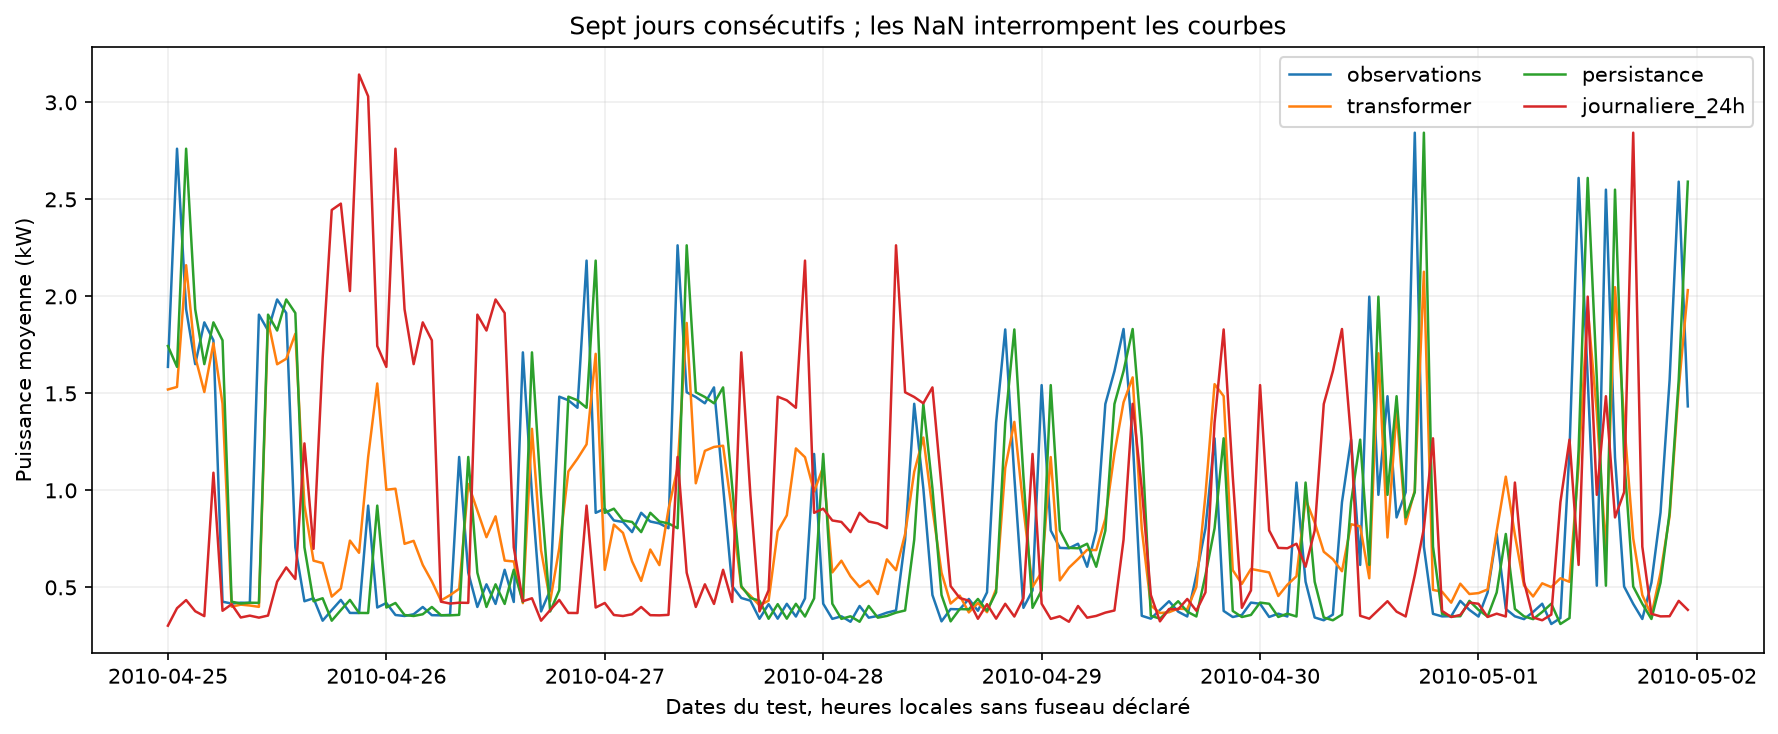

In [4]:
display(Code(inspect.getsource(modeles.EnergyTransformer),language='python'))
resultat_energie=experiences.energie(device)
print(json.dumps(resultat_energie['donnees'],ensure_ascii=False,indent=2))
print('Époque retenue :',resultat_energie['epoque_choisie'])
display(pd.DataFrame(resultat_energie['metriques_test_kw']).T)
print('Sept jours :',resultat_energie['graphe_sept_jours'])
for f in ['energie_pertes.png','energie_sept_jours.png']:voir(f)

### Réflexion — cinq questions

**1. Le Transformer améliore-t-il les deux références ?** La réponse est calculée
ci-dessous sur exactement les mêmes cibles. Persistance utilise la dernière heure
réellement observée ; la référence journalière utilise la première heure de la fenêtre.
Les erreurs sont évaluées après retour en kW. Le graphique commence au premier jour
entier du test et couvre 168 heures calendaires ; les NaN interrompent les courbes.

<!-- lecture-des-resultats -->
Les trois méthodes sont comparées sur **4 932 cibles identiques**. MAE et RMSE sont exprimées en kW ; la MSE est en kW². Le modèle retenu à l'époque 17 améliore les deux références sur MAE et RMSE. Les sept jours affichés comportent ici **0 heure sans prédiction** ; le tracé conserverait les interruptions si des fenêtres manquaient.

In [5]:
s=resultat_energie['metriques_test_kw']
oui=resultat_energie['transformer_ameliore_les_deux_references']
display(Markdown(('**Oui**' if oui else '**Non**')+' : amélioration simultanée de MAE et RMSE face aux deux références : '+str(oui)+'.'))
print('Rechargement :',resultat_energie['rechargement'])

**Oui** : amélioration simultanée de MAE et RMSE face aux deux références : True.

Rechargement : {'reussi': True, 'ecart_max': 0.0, 'tolerance': 1e-06, 'identique': True}


**2. Fenêtre de 168 heures.** Elle donnerait accès à une semaine et pourrait capturer
des habitudes hebdomadaires. Cette extension n'est pas entraînée ici. Elle demande
davantage de données et accroît le coût : les relations d'attention seraient 49 fois
plus nombreuses qu'avec 24 positions, sans garantie de meilleure prévision.

**3. Variables calendaires.** Heure et jour de semaine peuvent distinguer les cycles
quotidiens et les jours de repos. Leurs valeurs futures sont connues à la prévision.
Un codage cyclique sinus/cosinus éviterait une rupture artificielle entre 23 h et 0 h.

**4. Normalisation train seulement.** Utiliser validation ou test pour calculer les
statistiques introduirait une information future. Les mêmes statistiques train doivent
être conservées pour l'évaluation et une utilisation ultérieure.

**5. Puissance et énergie.** Une puissance moyenne P sur une durée Δt correspond à
E=P×Δt : en kW et en heures, E est en kWh. Pour une heure complète, la valeur numérique
coïncide. Pour une cible d'énergie issue des minutes, intégrer les puissances sur leurs
durées, et signaler la couverture manquante ; une moyenne de 45 minutes ne garantit
pas l'énergie exacte de l'heure entière sans hypothèse sur les minutes absentes.

## Exercice 2 — Mini-GPT depuis zéro

Le corpus original `corpus.txt` contient un récit et des observations semi-synthétiques,
écrits pour ce TP. L'alphabet est construit sur les 90 % initiaux ; tous les caractères
de validation sont vérifiés comme connus. Chaque segment est fenêtré séparément :
aucune fenêtre de 64 caractères ne traverse la frontière. Les cibles sont décalées
d'un caractère et la CrossEntropyLoss porte sur toutes les positions.

Deux blocs pré-LayerNorm : attention causale à quatre têtes, résiduel, seconde
LayerNorm, MLP 64→256→64 avec GELU et résiduel. Embeddings de dimension 64 ; dropout
0.1 et projection vers l'alphabet. Choix fixes : Adam(lr=0.003), batch 64, 30 époques,
poids retenus au minimum de perte de validation. La perplexité est par **caractère**.

class GPTBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.norm1 = nn.LayerNorm(64)
        self.attention = nn.MultiheadAttention(embed_dim=64, num_heads=4, dropout=0.1, batch_first=True)
        self.norm2 = nn.LayerNorm(64)
        self.mlp = nn.Sequential(nn.Linear(64, 256), nn.GELU(), nn.Linear(256, 64), nn.Dropout(0.1))

    def forward(self, x, masque):
        normalise = self.norm1(x)
        attention, _ = self.attention(normalise, normalise, normalise, attn_mask=masque, need_weights=False)
        x = x + attention
        return x + self.mlp(self.norm2(x))

class MiniGPT(nn.Module):
    def __init__(self, taille_vocabulaire):
        super().__init__()
        self.tokens = nn.Embedding(taille_vocabulaire, 64)
        self.positions = nn.Embedding(64, 64)
        self.blocs = nn.ModuleList([GPTBlock(), GPTBlock()])
        self.sortie = nn.Linear(64, taille_vocabulaire)

    def representations(self, ids):
        longueur = ids.size(1)
        if not 1 <= longueur <= 64:
            raise ValueError('Une séquence GPT contient de 1 à 64 caractères.')
        x = self.tokens(ids) + self.positions(torch.arange(longueur, device=ids.device))
        masque = torch.triu(torch.ones(longueur, longueur, dtype=torch.bool, device=ids.device), diagonal=1)
        for bloc in self.blocs:
            x = bloc(x, masque)
        return x

    def forward(self, ids):
        return self.sortie(self.representations(ids))

mini_gpt : entraînement terminé réutilisé.


{
  "caracteres_total": 16197,
  "taille_vocabulaire": 41,
  "frontiere_train": 14577,
  "fenetres_train": 908,
  "fenetres_validation": 25,
  "longueur": 64,
  "pas_train": 16,
  "pas_validation": 64,
  "vocabulaire_construit_sur_train": true,
  "fenetres_traversant_frontiere": 0
}
Perte validation choisie : 1.1477129459381104
Perplexité/caractère : 3.1509782051219033
Tests : {
  "causalite": {
    "reussi": true,
    "position_modifiee": 40,
    "positions_comparees": "0 à 39",
    "ecart_max": 0.0,
    "tolerance": 1e-06
  },
  "formes": {
    "entree": [
      2,
      64
    ],
    "representations": [
      2,
      64,
      64
    ],
    "logits": [
      2,
      64,
      41
    ],
    "cibles": [
      2,
      64
    ]
  },
  "rechargement": {
    "reussi": true,
    "ecart_max": 0.0,
    "tolerance": 1e-06,
    "identique": true
  }
}


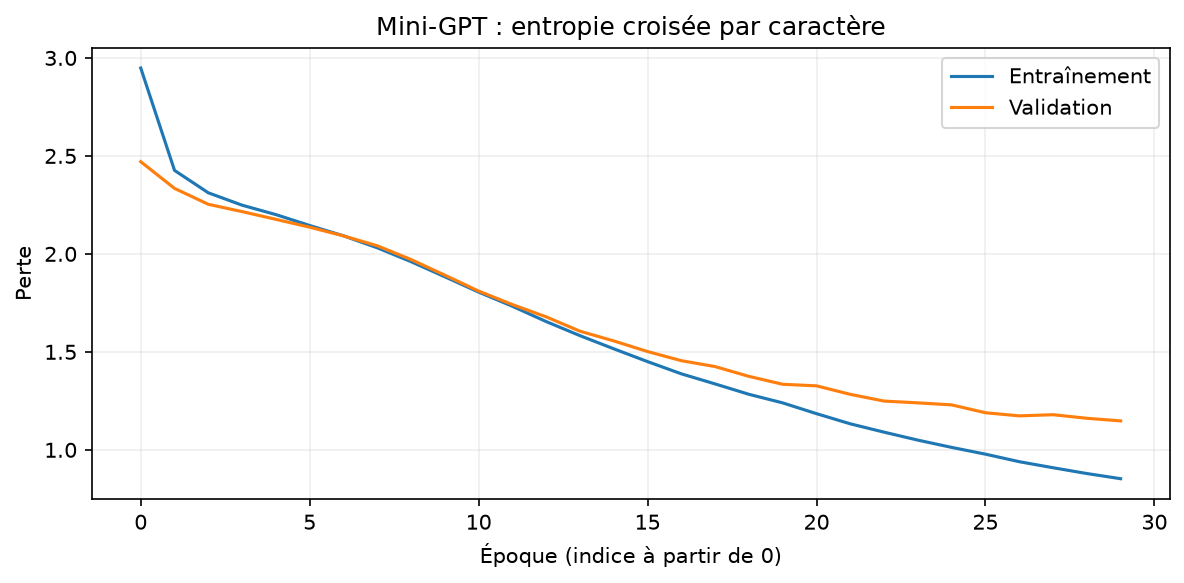


Température 0.5 | nouveaux caractères : 200
la bibliothèques poue deux courbes avant la pause.
le chercheur cuisinière hanité avec une partion pet découve de la techise comparait.
le technicien con avec une partil.


la technicienne chercheurchaque con avec u

Température 1.0 | nouveaux caractères : 200
la bibliothèques poue unettouvele une partie du le exa tamine découvelite sematile trable lechois, ace partode connue une partis. etine nouveliote le d'éparngé parent dans déce du bleaux éthèquait, d'arquent rece es

Température 1.5 | nouveaux caractères : 200
la bibliothèques poue unettouvele fause. un me contervérifie évuarit les, shmairchanir icienait,
daite précome dans vériuelon aciaiainenne la vait déqu'aprent. partis cunissite,

chanicicienst monet ime phaqcarde co


In [6]:
for classe in [modeles.GPTBlock,modeles.MiniGPT]:display(Code(inspect.getsource(classe),language='python'))
resultat_gpt=experiences.mini_gpt(device)
print(json.dumps(resultat_gpt['corpus'],ensure_ascii=False,indent=2))
print('Perte validation choisie :',resultat_gpt['meilleure_perte_suivie'])
print('Perplexité/caractère :',resultat_gpt['perplexite_validation_par_caractere'])
print('Tests :',json.dumps(resultat_gpt['tests'],ensure_ascii=False,indent=2))
voir('gpt_pertes.png')
for g in resultat_gpt['generations']:
    print('\nTempérature',g['temperature'],'| nouveaux caractères :',g['nouveaux_caracteres'])
    print(g['texte_complet'])

### Réflexion — trois questions

**1. Sans masque causal.** À l'entraînement, une position pourrait voir le caractère
qu'elle doit prédire dans une position future. Cette fuite ferait baisser la perte sans
apprendre la tâche utilisable en génération. Le test numérique modifie la position 40
et compare les logits 0 à 39 en eval(), avec une tolérance absolue de 1e-6.

**2. Température.** La distribution est softmax(logits/T). Une température de 0.5
concentre le tirage, 1.0 garde l'échelle apprise et 1.5 augmente la diversité, souvent
au prix de la cohérence. Les trois sorties utilisent la même amorce et une graine
réinitialisée à 2026 ; chacune contient exactement 200 nouveaux caractères. Leur
comparaison est qualitative et ne mesure aucune compréhension générale.

**3. Décalage des cibles.** L'entrée à la position t sert à prédire le caractère t+1.
Sans ce décalage, le réseau pourrait simplement apprendre à copier le caractère déjà
présent. Le vocabulaire et les poids sont sauvegardés ensemble avec leurs empreintes.

## Exercice 3 — Mini-BERT depuis zéro

Les phrases originales de `corpus_bert.txt` sont séparées à 80/20 **avant** de construire
le vocabulaire par mots. Les identifiants PAD=0, UNK=1, CLS=2, SEP=3 et MASK=4 sont
réservés. Chaque phrase forme [CLS] mots [SEP] [PAD]… sur 32 positions maximum.
Les inconnus de validation sont comptés, jamais ajoutés au vocabulaire.

Environ 15 % des tokens ordinaires sont sélectionnés, avec au moins une sélection par
phrase non vide. Cette garantie augmente légèrement le taux pour les phrases courtes.
Pour les sélectionnés : 80 % MASK, 10 % mot ordinaire aléatoire, 10 % inchangés.
Les labels sont copiés **avant** corruption et valent -100 hors sélection, y compris
pour les tokens spéciaux. Les sélectionnés inchangés contribuent bien à la perte.

Deux encodeurs bidirectionnels, quatre têtes, embeddings 64, FF=256, dropout=0.1,
masque de padding et aucune causalité. Choix fixes : Adam(lr=0.001), batch 64,
40 époques, sélection sur perte de validation. La corruption de validation est fixée
par la graine 2026 et son SHA-256 ; seule la corruption d'entraînement varie.

<!-- lecture-des-resultats -->
La perte de validation retenue est **1.147713 par caractère**, soit une perplexité de **3.150978**. Les sorties enregistrées contiennent des fragments familiers mais aussi des mots déformés et des phrases incorrectes, particulièrement à température élevée. Ce résultat sur un petit corpus à patrons récurrents ne mesure pas une compréhension. La validation sert au choix des poids ; aucun test linguistique indépendant n'est utilisé.

class MiniBERT(nn.Module):
    def __init__(self, taille_vocabulaire):
        super().__init__()
        self.tokens = nn.Embedding(taille_vocabulaire, 64, padding_idx=PAD)
        self.positions = nn.Embedding(32, 64)
        couche = nn.TransformerEncoderLayer(d_model=64, nhead=4, dim_feedforward=256,
            dropout=0.1, batch_first=True)
        self.encodeur = nn.TransformerEncoder(couche, num_layers=2, enable_nested_tensor=False)
        self.sortie = nn.Linear(64, taille_vocabulaire)

    def representations(self, ids, masque_padding):
        if ids.size(1) > 32 or masque_padding.dtype != torch.bool:
            raise ValueError('BERT exige au plus 32 tokens et un masque booléen de padding.')
        x = self.tokens(ids) + self.positions(torch.arange(ids.size(1), device=ids.device))
        return self.encodeur(x, src_key_padding_mask=masque_padding)

    def forward(self, ids, masque_padding):
        return self.sortie(self.representations(ids, masque_padding))

mini_bert : entraînement terminé réutilisé.


{
  "phrases_total": 446,
  "phrases_train": 356,
  "phrases_validation": 90,
  "taille_vocabulaire": 518,
  "tokens_ordinaires_validation": 954,
  "tokens_unk_validation": 38,
  "taux_unk_validation": 0.03983228653669357,
  "vocabulaire_train_seulement": true,
  "phrases_communes": 0
}
Corruption validation fixe : {'selectionnes': 144, 'ordinaires': 916, 'branche_mask': 118, 'branche_aleatoire': 10, 'branche_inchangee': 16, 'graine': 2026, 'sha256': '62e5c9790693baa1d58079398cf1413f59fa6a362a2c3e7592e628ce0c08cc00', 'fixe_sur_toutes_les_epoques': True}
Exactitude positions sélectionnées : 0.5416666865348816
Exactitude sous-ensemble remplacé par MASK : 0.5169491767883301
Tests : {
  "padding": {
    "reussi": true,
    "masque_padding_inchange": true,
    "positions_padding_modifiees": 77,
    "ecart_max": 0.0,
    "tolerance": 1e-06
  },
  "formes": {
    "entree": [
      4,
      32
    ],
    "representations": [
      4,
      32,
      64
    ],
    "logits": [
      4,
      32,

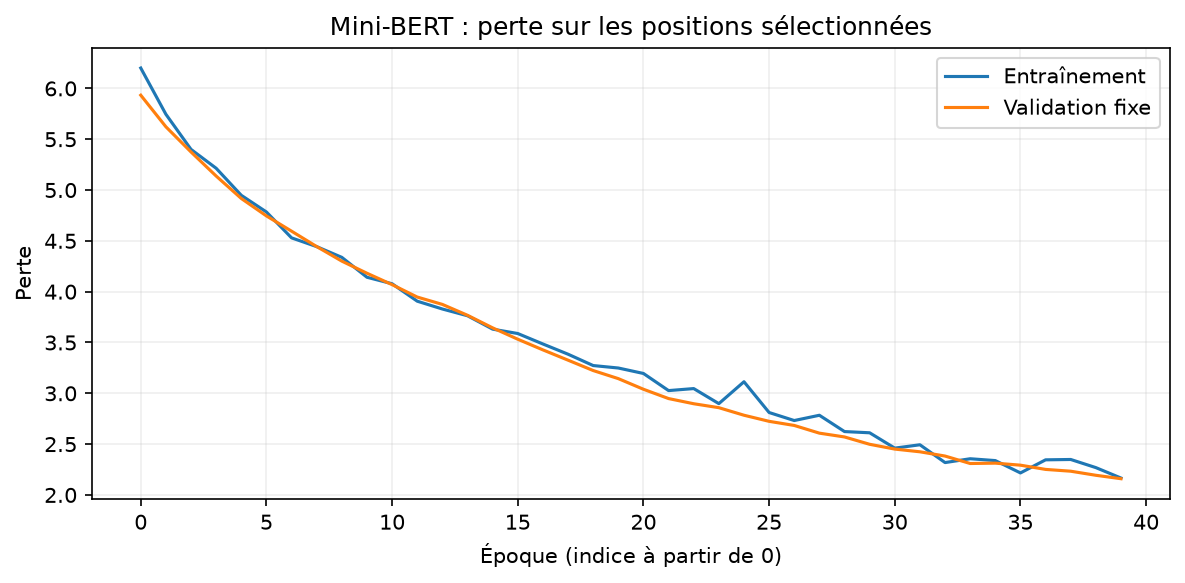

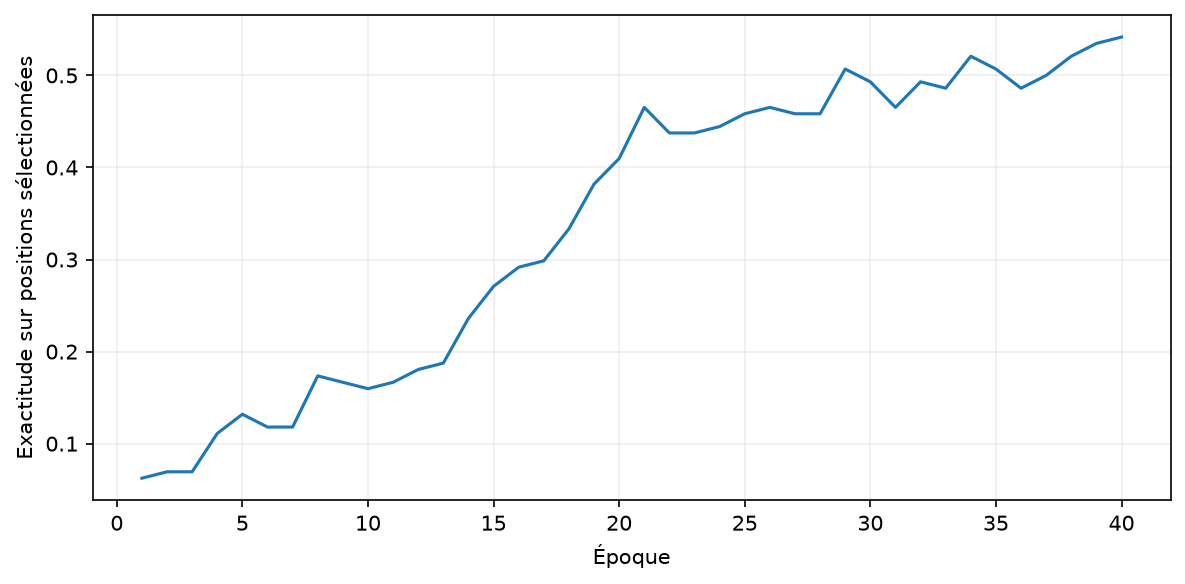


 [CLS] la conductrice vérifie [MASK] direction du chemin sans modifier les observations précédentes [SEP] | cible : la


,mot,probabilite
0,la,0.634878
1,le,0.296131
2,modifier,0.007258



 [CLS] le jardin de [MASK] bibliothèque [UNK] un autre rythme [SEP] | cible : la


,mot,probabilite
0,une,0.666606
1,un,0.117856
2,la,0.035868



 [CLS] le jardinier prépare [MASK] terre humide selon le programme prévu [SEP] | cible : la


,mot,probabilite
0,une,0.426763
1,un,0.178731
2,la,0.142169



 [CLS] la voisine protège [MASK] fleurs fragiles à la fin de la journée [SEP] | cible : les


,mot,probabilite
0,les,0.873791
1,une,0.042025
2,un,0.018347


In [7]:
display(Code(inspect.getsource(modeles.MiniBERT),language='python'))
resultat_bert=experiences.mini_bert(device)
print(json.dumps({k:v for k,v in resultat_bert['corpus'].items() if not k.startswith('indices')},ensure_ascii=False,indent=2))
print('Corruption validation fixe :',resultat_bert['corruption_validation'])
print('Exactitude positions sélectionnées :',resultat_bert['accuracy_validation_selection'])
print('Exactitude sous-ensemble remplacé par MASK :',resultat_bert['accuracy_validation_remplacements_mask'])
print('Tests :',json.dumps(resultat_bert['tests'],ensure_ascii=False,indent=2))
for f in ['bert_pertes.png','bert_accuracy.png']:voir(f)
for e in resultat_bert['exemples_masques']:
    print('\n',' '.join(e['tokens_masques']),'| cible :',e['cible'])
    display(pd.DataFrame(e['top3']))

### Réflexion — trois questions

**1. Contexte à droite.** BERT reçoit une phrase dont certaines positions sont
corrompues ; aucune contrainte causale n'interdit les mots à droite. Le padding
reste exclu des clés d'attention. Changer les identifiants de padding en gardant
exactement le même masque ne doit pas changer les logits utiles : test à 1e-6.

**2. Perte sur positions sélectionnées.** Les mots non sélectionnés sont déjà visibles ;
les inclure favoriserait une copie facile et dominerait l'objectif MLM. -100 les ignore.
Les 10 % sélectionnés inchangés restent supervisés selon le protocole 80/10/10.
L'exactitude publiée porte sur toute la sélection, pas sur la totalité des positions ;
le sous-ensemble remplacé par MASK est fourni séparément.

**3. Différence avec GPT.** Le mini-BERT reconstruit des trous à l'aide des deux côtés,
alors que GPT apprend la distribution du prochain caractère à partir du passé. BERT
n'est donc pas directement entraîné à prolonger une séquence par la même boucle.

## Bilan et limites

Ces six modèles ont des objectifs et des unités de pertes différents. Les scores
énergétiques dépendent d'un seul foyer et d'un découpage historique. Les corpus de
langage sont petits, restreints et partiellement construits par patrons ; une bonne
exactitude MLM ou une continuation familière peut refléter leur mémorisation.
Les modèles préentraînés ont d'autres corpus et tailles : cette démonstration ne les
compare pas équitablement aux mini-modèles. Aucun entraînement supplémentaire à
168 heures et aucune recherche de scores parfaits ne sont présentés.

<!-- lecture-des-resultats -->
L'exactitude est de **54.17 %** sur les **144 positions sélectionnées** de validation, y compris les positions sélectionnées inchangées. Sur les seules positions remplacées par MASK, elle vaut **51.69 %**. Les 38 UNK sur 954 mots de validation (3,98 %) ne sont pas sélectionnés pour le MLM. Les patrons récurrents, le petit corpus et le choix des poids sur cette même validation limitent la portée du score ; il ne s'agit pas d'un test indépendant.

In [8]:
rapport={'statut':'termine','date_utc':datetime.now(timezone.utc).isoformat(),'environnement':environnement,
    'support':{'notebook':'architecture_transformer.ipynb','cellules':56,'exercices':[37,54],
        'sha256':'17dbf76ffdd201515a8bd9d20c487e53b2e352e7f5392dbdb09f14a10c8495ba'},
    'sinus':resultat_sinus,'preentraines':resultat_preentraine,'energie':resultat_energie,
    'mini_gpt':resultat_gpt,'mini_bert':resultat_bert,
    'corpus':json.loads((ROOT/'corpus_origine.json').read_text(encoding='utf-8')),
    'figures':sorted(p.relative_to(ROOT).as_posix() for p in (ROOT/'figures').glob('*.png')),
    'validation':{'aucune_selection_sur_test':True,'normalisation_train_seulement':True,
        'fenetres_gpt_disjointes':True,'vocabulaire_bert_train_seulement':True,
        'validation_mlm_fixe':True,'causalite_gpt':resultat_gpt['tests']['causalite'],
        'padding_bert':resultat_bert['tests']['padding'],'questions_reflexion_repondues':11}}
ecrire_json(ROOT/'resultats_tp4.json',rapport)
table=[]
for nom,r in resultat_sinus['modeles'].items():table.append({'modele':nom,'parametres':r['parametres'],**r['metriques_test']})
table.append({'modele':'energy_transformer','parametres':resultat_energie['parametres'],**resultat_energie['metriques_test_kw']['transformer']})
display(pd.DataFrame(table))
print('Mini-GPT : CE validation',resultat_gpt['meilleure_perte_suivie'])
print('Mini-BERT : exactitude sélection',resultat_bert['accuracy_validation_selection'])
print('Rapport réel enregistré : resultats_tp4.json | figures :',len(rapport['figures']))

,modele,parametres,mse,mae,rmse,cibles
0,rnn,321,0.000028,0.004562,0.005256,40
1,lstm,1233,0.000003,0.001355,0.001582,40
2,transformer_sinus,2433,0.000006,0.002041,0.002349,40
3,energy_transformer,26273,0.237783,0.339984,0.487630,4932


Mini-GPT : CE validation 1.1477129459381104
Mini-BERT : exactitude sélection 0.5416666865348816
Rapport réel enregistré : resultats_tp4.json | figures : 8


## Sources et attribution

- **Pr. Mohamed Youssfi**, `architecture_transformer.ipynb` : exemples RNN/LSTM/Transformer
  (cellules 8–29), démonstrations préentraînées (31–35), exercices (37–54).
- **Hebrail, G. et Berard, A.**, [Individual Household Electric Power Consumption](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption), UCI, [DOI](https://doi.org/10.24432/C58K54), CC BY 4.0.
- [PyTorch](https://pytorch.org/docs/stable/), [Hugging Face Transformers](https://huggingface.co/docs/transformers/),
  [GPT-2](https://huggingface.co/openai-community/gpt2) (MIT),
  [BERT multilingue](https://huggingface.co/google-bert/bert-base-multilingual-cased) (Apache 2.0),
  [UV](https://docs.astral.sh/uv/).

Les corpus originaux sont décrits dans `corpus_origine.json`. Aucun dataset volumineux,
modèle préentraîné ou support original n'est destiné au suivi Git. Les graphiques sont
produits par nos expériences et ne reproduisent pas les figures du support.